# Sales Forecasting: Weekly and Monthly Forecasts

The model predicts 
- `revenue_kes`: money made (KES)
- `units_sold`: number of items sold
- `transaction_count`: number of sales receipts

for every store and product.

## 1. Setting up

- Libraries

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score

- Data

In [2]:
data = "../Data/processed_data/"

products = pd.read_csv(data + "Products_cleaned.csv")
promos = pd.read_csv(data + "Promotions_cleaned.csv", parse_dates=["start_date", "end_date"])
sales = pd.read_csv(data + "sales.csv", parse_dates=["transaction_date", "week_start", "month_start"])
inflation = pd.read_csv(data + "Inflation_cleaned.csv", parse_dates=["month"])
holidays = pd.read_csv(data + "Holidays_cleaned.csv", parse_dates=["date"])

In [3]:
# Display options
pd.set_option("display.max_colwidth", None)
pd.set_option("display.float_format", "{:.2f}".format)
pd.set_option("display.max_columns", None)

## 2. Weekly and Monthly Tables

- Planned Promotions  
Promos table currently has a row for each promo, we need a row for each store, product and day, as it will be important to getting the promotion days in a week or month

In [4]:
stores = ";".join(sorted(sales["store_id"].unique()))
promotion_rows = promos.copy()

# One row for each day of the promotion
def get_promotion_dates(row):
    return pd.date_range(row["start_date"], row["end_date"]).tolist()
promotion_rows["date"] = promotion_rows.apply(get_promotion_dates, axis=1)

# One row for each store of the promotion
promotion_rows["store_id"] = promotion_rows["store_scope"].replace("ALL", stores).str.split(";")
promotion_rows = promotion_rows.explode("date").explode("store_id")
promotion_rows["date"] = pd.to_datetime(promotion_rows["date"])

# Entire category promotions apply to all products in it
product_promos = promotion_rows[promotion_rows["scope_type"] == "SKU"]
category_promos = promotion_rows[promotion_rows["scope_type"] == "Category"].drop(columns="product_id")
category_promos = category_promos.merge(products[["product_id", "category"]], on="category")

promo_by_day = (pd.concat([product_promos, category_promos])
                .groupby(["store_id", "product_id", "date"], as_index=False)["discount_pct"].max())

In [5]:
# Inflation rate for each month
inflation_by_month = inflation.set_index(inflation["month"].dt.to_period("M"))["inflation_12m_pct"]

# The target columns and the first and last day in the data
target_columns = ["revenue_kes", "units_sold", "transaction_count"]
first_day = sales["transaction_date"].min()
last_day = sales["transaction_date"].max()

In [6]:
# To score the model predictions against actual
# Mean Average Error, WAPE (sum of absolute forecasting errors), R-squared

def model_scores(model_name, actual, predicted):
    rows = []
    for target in target_columns:
        rows.append({"Model": model_name, "Target": target,
                     "MAE": round(mean_absolute_error(actual[target], predicted[target]), 2),
                     "WAPE (%)": round((actual[target] - predicted[target]).abs().sum() 
                                       / actual[target].sum() * 100, 1),
                     "R²": round(r2_score(actual[target], predicted[target]), 2)})
    return pd.DataFrame(rows)

## 3. Weekly Forecasts

### a. Weekly Dataset Prep

- Sales per store

In [7]:
# Sales per store, product and week (Only for complete weeks)
first_monday = first_day + pd.to_timedelta((7 - first_day.day_of_week) % 7, unit="D")
complete_weeks = pd.date_range(first_monday, last_day - pd.Timedelta(days=6), freq="7D")

weekly_data = (sales[sales["week_start"].isin(complete_weeks)].groupby(
            ["week_start", "store_id", "product_id"], as_index=False).agg(
                revenue_kes=("revenue_kes", "sum"),
                units_sold=("quantity", "sum"),
                transaction_count=("transaction_id", "nunique")))

- Weeks with no sales for a given product filled with 0, so they are not skipped

In [8]:
first_sale_week = (weekly_data.groupby(["store_id", "product_id"], as_index=False)["week_start"].min()
                   .rename(columns={"week_start": "first_sale_week"}))

# Store-product paring for every complete week, from first sale onwards
all_weeks = first_sale_week.merge(pd.DataFrame({"week_start": complete_weeks}), how="cross")
all_weeks = all_weeks[all_weeks["week_start"] >= all_weeks["first_sale_week"]].drop(columns="first_sale_week")

weekly_data = all_weeks.merge(weekly_data, how="left", on=["week_start", "store_id", "product_id"])
weekly_data[target_columns] = weekly_data[target_columns].fillna(0)

- Adding features to weekly set

In [9]:
weekly_data = weekly_data.merge(products[["product_id", "category"]], on="product_id")

# Payday days in each week
days = pd.DataFrame({"date": pd.date_range(first_day, last_day)})
days["week_start"] = days["date"] - pd.to_timedelta(days["date"].dt.day_of_week, unit="D")
days_left_in_month = days["date"].dt.days_in_month - days["date"].dt.day
days["is_payday"] = ((days_left_in_month <= 5) | (days["date"].dt.day <= 2)).astype(int)
payday_days_per_week = (days.groupby("week_start", as_index=False)["is_payday"].sum()
                        .rename(columns={"is_payday": "payday_days"}))
weekly_data = weekly_data.merge(payday_days_per_week, on="week_start")

# Holiday weeks
holiday_weeks = holidays["date"] - pd.to_timedelta(holidays["date"].dt.day_of_week, unit="D")
weekly_data["is_holiday"] = weekly_data["week_start"].isin(holiday_weeks).astype(int)

# Discounts
promo_by_day["week_start"] = promo_by_day["date"] - pd.to_timedelta(promo_by_day["date"].dt.day_of_week, unit="D")
weekly_discount = (promo_by_day.groupby(["week_start", "store_id", "product_id"], as_index=False)["discount_pct"].max())
weekly_data = weekly_data.merge(weekly_discount, how="left", on=["week_start", "store_id", "product_id"])
weekly_data["discount_pct"] = weekly_data["discount_pct"].fillna(0)

# Month, and the inflation rate of the month in the middle of the week
weekly_data["month"] = weekly_data["week_start"].dt.month
middle_of_week = weekly_data["week_start"] + pd.Timedelta(days=3)
weekly_data["inflation_12m_pct"] = middle_of_week.dt.to_period("M").map(inflation_by_month)

- Adding previous sales columns (For each target we add two columns that only use earlier weeks)

In [10]:
# Adds two columns for each target, using earlier periods: previous and recent averages for the targets
def add_past_sales(data, period_column, window):
    data = data.sort_values(["store_id", "product_id", period_column]).reset_index(drop=True)

    past_sales_columns = []
    for target in target_columns:
        product_sales = data.groupby(["store_id", "product_id"])[target]
        data["previous_" + target] = product_sales.shift(1)
        data["recent_avg_" + target] = product_sales.transform(
            lambda sales: sales.shift(1).rolling(window, min_periods=1).mean())
        past_sales_columns += ["previous_" + target, "recent_avg_" + target]

    return data.dropna(subset=past_sales_columns), past_sales_columns # Removing first week/month as they have no sales data

# Weekly: the average of the previous 4 weeks
weekly_data, past_sales_columns = add_past_sales(weekly_data, "week_start", 4)

- Encoding categorical variables

_Encoding categorical variables as integers (integer / label encoding)_

In [11]:
# Defining function that will be used for month as well
def encode_categories(data):
    for column in ["store_id", "product_id", "category"]:
        data[column + "_code"] = data[column].astype("category").cat.codes
    return data

weekly_data = encode_categories(weekly_data)

weekly_features = (["month", "payday_days", "is_holiday", "discount_pct", "inflation_12m_pct",
                    "store_id_code", "product_id_code", "category_code"] + past_sales_columns)

print("Weekly table:", weekly_data.shape)

Weekly table: (134258, 21)


In [12]:
weekly_data.head()

,store_id,product_id,week_start,revenue_kes,units_sold,transaction_count,category,payday_days,is_holiday,discount_pct,month,inflation_12m_pct,previous_revenue_kes,recent_avg_revenue_kes,previous_units_sold,recent_avg_units_sold,previous_transaction_count,recent_avg_transaction_count,store_id_code,product_id_code,category_code
1,S01,SKU0002,2024-10-14,6450.00,43.00,16.00,Food Staples,0,1,0.00,10,2.72,14190.00,14190.00,127.00,127.00,43.00,43.00,0,1,4
2,S01,SKU0002,2024-10-21,11550.00,77.00,35.00,Food Staples,2,1,0.00,10,2.72,6450.00,10320.00,43.00,85.00,16.00,29.50,0,1,4
3,S01,SKU0002,2024-10-28,15000.00,100.00,56.00,Food Staples,6,0,0.00,10,2.72,11550.00,10730.00,77.00,82.33,35.00,31.33,0,1,4
4,S01,SKU0002,2024-11-04,11700.00,78.00,35.00,Food Staples,0,0,0.00,11,2.75,15000.00,11797.50,100.00,86.75,56.00,37.50,0,1,4
5,S01,SKU0002,2024-11-11,9300.00,62.00,38.00,Food Staples,0,0,0.00,11,2.75,11700.00,11175.00,78.00,74.50,35.00,35.50,0,1,4


### b. Splitting Data

Since this is a forecasting model, the data is split chronologically rather than randomly.

The data is split by time into training (first 70% of the periods), validation (next 15%) and test (last 15%) sets, & it learns from the training set.
- The **validation** set is used to compare the models and the feature sets, and to make every choice.
- The **test** set is used only once, in the final results at the end, so those scores show how the chosen models would perform on data it has not seen.

- Split function, used for both month and weekly split

In [13]:
# Splitting and separating predictors from targets

def split_by_time(data, period_column, features, period_name):
    data = data.dropna(subset=features)        
    periods = sorted(data[period_column].unique()) # Ordering data by dates
    train_end = int(len(periods) * 0.70)
    validation_end = int(len(periods) * 0.85)
 
    train = data[data[period_column].isin(periods[:train_end])]
    validation = data[data[period_column].isin(periods[train_end:validation_end])]
    test = data[data[period_column].isin(periods[validation_end:])]
 
    print("Training", period_name + ":", train_end, "| Validation", period_name + ":", validation_end - train_end,
          "| Test", period_name + ":", len(periods) - validation_end)
    
    return (train[features], train[target_columns], validation[features], validation[target_columns],
            test[features], test[target_columns])

X_train, y_train, X_validation, y_validation, X_test, y_test = split_by_time(weekly_data, "week_start", weekly_features, "weeks")

Training weeks: 71 | Validation weeks: 15 | Test weeks: 16


### c. Training, making predictions and evaluating the model

1. MAE: Average prediction error in the target's original units (the lower the better).
2. WAPE: Total prediction error as a percentage of total actual sales (the lower the better).
3. R²: Measures how much variation in sales the model explains (the closer it is to 1 the better).

**Why WAPE instead of MAPE.** MAPE divides each row's error by its actual sales. Rows with zero sales make it undefined or extremely large. WAPE adds up all the errors and divides once by total sales, so zero-sales are not a problem.

- Training is done on the training set, and prediction and scoring is done on the validation set

In [14]:
# Baseline (Function used for both monthly and weekly models)
# The baseline guesses that sales will equal the previous period's sales

def previous_period_baseline(X_eval):
    baseline = X_eval[["previous_" + target for target in target_columns]].copy()
    baseline.columns = target_columns
    return baseline

# Previous week's sales as the baseline prediction
weekly_baseline = previous_period_baseline(X_validation)
weekly_baseline_results = model_scores("Baseline", y_validation, weekly_baseline)
weekly_baseline_results

,Model,Target,MAE,WAPE (%),R²
0,Baseline,revenue_kes,3094.31,52.20,0.50
1,Baseline,units_sold,16.54,51.30,0.53
2,Baseline,transaction_count,7.43,43.10,0.62


- Training function (For both weekly and monthly models)

In [15]:
# selected models for training are gradient boosting and random forest

def fit_predict(model_type, X_train, y_train, X_eval):
    predictions = pd.DataFrame(index=X_eval.index)

    for target in target_columns:
        # Instantiate the model
        if model_type == "Gradient Boosting":
            model = HistGradientBoostingRegressor(max_iter=100, max_depth=4, random_state=42)
        else:
            model = RandomForestRegressor(n_estimators=100, n_jobs=-1, random_state=42)
        # Train the model
        model.fit(X_train, y_train[target])
        # Make predictions
        predictions[target] = model.predict(X_eval)
    return predictions

- Gradient boosting

In [16]:
 # Train & predict model using function (fit_predict)
weekly_boost_predictions = fit_predict("Gradient Boosting", X_train, y_train, X_validation)
weekly_boost_results = model_scores( "Gradient Boosting", y_validation, weekly_boost_predictions)
weekly_boost_results

,Model,Target,MAE,WAPE (%),R²
0,Gradient Boosting,revenue_kes,1943.46,32.80,0.83
1,Gradient Boosting,units_sold,10.08,31.20,0.84
2,Gradient Boosting,transaction_count,4.37,25.40,0.88


- Random Forest

In [17]:
# Train and predict with fit_predict
weekly_forest_predictions = fit_predict("Random Forest", X_train, y_train, X_validation)

weekly_forest_results = model_scores("Random Forest", y_validation, weekly_forest_predictions)
weekly_forest_results

,Model,Target,MAE,WAPE (%),R²
0,Random Forest,revenue_kes,2019.48,34.10,0.81
1,Random Forest,units_sold,10.28,31.90,0.83
2,Random Forest,transaction_count,4.49,26.00,0.87


_Both models do much better than the benchmark, gradient boosting brings the error down to 32.8%, 31.2% and 25.4%, and the random forest to 34.1%, 31.9% and 26.0% for the revenue, units and transactions respectively, an improvement of 17 to 20 percentage points over the baseline. The average error (MAE) falls by about 40%, for example from KES 3,094 to KES 1,943 for revenue with gradient boosting, and R² rises from 0.50–0.62 for the baseline to 0.81–0.88 for the models, meaning they explain most of the week-to-week variation in sales. Gradient boosting has the lower error on all three targets, but only by 0.6 to 1.3 points, so the two models are close. Transactions are the easiest target to predict and revenue the hardest, probably because revenue depends on both how many items are sold and their prices._

### d. Determining whether Inflation, promotion and calendar features improve the weekly  model or not
- Model is trained with these features removed, to spot any differences in the WAPE (the lower the better) 

In [18]:
# Retrains the model with different sets of features and shows the error of each version side by side.
def compare_features(all_features, removable_features, X_train, y_train, X_eval, y_eval, model_type):
    feature_sets = {"All features": all_features}
    for feature, label in removable_features.items():
        feature_sets["Without " + label] = [f for f in all_features if f != feature]
    feature_sets["Core only"] = [f for f in all_features if f not in removable_features]

    results = []
    for set_name, features in feature_sets.items():
        predictions = fit_predict(model_type, X_train[features], y_train, X_eval[features])
        results.append(model_scores(set_name, y_eval, predictions))

    # One row per target, one column per feature set, values = WAPE (%)
    table = pd.concat(results).pivot_table(index="Target", columns="Model", values="WAPE (%)")[list(feature_sets)]
    table.columns.name = "Features used"

    table.plot.bar(rot=0, figsize=(11, 4), title=model_type + ": error with different sets of features")
    plt.xlabel("What is being predicted")
    plt.ylabel("Error (WAPE %), lower is better")
    plt.legend(title="Features used", bbox_to_anchor=(1.01, 1), loc="upper left")
    plt.show()
    return table

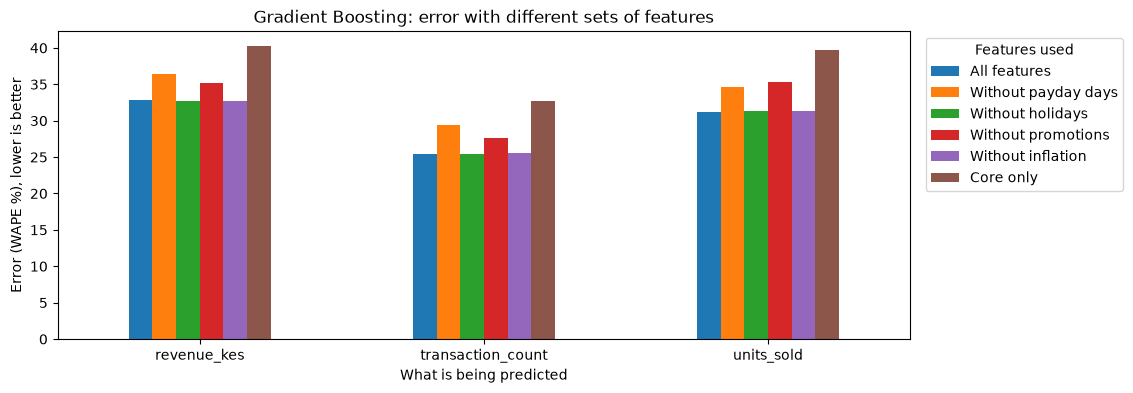

Features used,All features,Without payday days,Without holidays,Without promotions,Without inflation,Core only
Target,,,,,,
revenue_kes,32.80,36.40,32.70,35.20,32.70,40.30
transaction_count,25.40,29.40,25.40,27.60,25.50,32.70
units_sold,31.20,34.60,31.30,35.30,31.30,39.70


In [19]:
# The features to test, and the label shown for each one in the chart
weekly_removable_features = {"payday_days": "payday days", "is_holiday": "holidays",
                             "discount_pct": "promotions", "inflation_12m_pct": "inflation"}

compare_features(weekly_features, weekly_removable_features, X_train, y_train, X_validation, y_validation, "Gradient Boosting")

*For weekly forecasting, the full model (all features included) performs better than the core model (excluding the additional features). Removing payday_days increases WAPE by approximately 4-5 percentage points, while removing discount_pct increases it by 2-3 points. This suggests that payday and promotions contribute to better predictions. Removing inflation or public holidays has little effect, with changes of 0.3 points or less*

## 4. Monthly Forecasts

- These follow the same steps as the weekly forecasts, but uses months instead of weeks

### a. Monthly Dataset Prep

- Sales per store, product and month

In [20]:
all_months = pd.date_range(first_day.to_period("M").to_timestamp(), last_day, freq="MS")
last_day_of_month = all_months + pd.offsets.MonthEnd(0)
complete_months = all_months[(all_months >= first_day) & (last_day_of_month <= last_day)]

monthly_data = (sales[sales["month_start"].isin(complete_months)]
                .groupby(["month_start", "store_id", "product_id"], as_index=False)
                .agg(revenue_kes=("revenue_kes", "sum"),
                     units_sold=("quantity", "sum"),
                     transaction_count=("transaction_id", "nunique")))

- Months with no sales (0)

In [21]:
first_sale_month = (monthly_data.groupby(["store_id", "product_id"], as_index=False)["month_start"].min()
                    .rename(columns={"month_start": "first_sale_month"}))

# Every store-product paired with every complete month, from its first sale onward
all_months = first_sale_month.merge(pd.DataFrame({"month_start": complete_months}), how="cross")
all_months = all_months[all_months["month_start"] >= all_months["first_sale_month"]].drop(columns="first_sale_month")

monthly_data = all_months.merge(monthly_data, how="left", on=["month_start", "store_id", "product_id"])
monthly_data[target_columns] = monthly_data[target_columns].fillna(0)

- Adding features to monthly set (Similar to weekly, with the exception of payday_days since every mont has paydays)

In [22]:
monthly_data = monthly_data.merge(products[["product_id", "category"]], on="product_id")

# Holiday months
holiday_months = holidays["date"].dt.to_period("M").dt.to_timestamp()
monthly_data["is_holiday"] = monthly_data["month_start"].isin(holiday_months).astype(int)

# Highest discount in the month
promo_by_day["month_start"] = promo_by_day["date"].dt.to_period("M").dt.to_timestamp()
monthly_discount = (promo_by_day.groupby(["month_start", "store_id", "product_id"], as_index=False)["discount_pct"].max())
monthly_data = monthly_data.merge(monthly_discount, how="left", on=["month_start", "store_id", "product_id"])
monthly_data["discount_pct"] = monthly_data["discount_pct"].fillna(0)

# Month, and the inflation rate
monthly_data["month"] = monthly_data["month_start"].dt.month
monthly_data["inflation_12m_pct"] = monthly_data["month_start"].dt.to_period("M").map(inflation_by_month)

- Adding previous sales (monthly lag)

In [23]:
# Monthly: the average of the previous 3 months
monthly_data, past_sales_columns = add_past_sales(monthly_data, "month_start", 3)

- Encoding categorical variables as integers

In [24]:
monthly_data = encode_categories(monthly_data)

monthly_features = (["month", "is_holiday", "discount_pct", "inflation_12m_pct",
                     "store_id_code", "product_id_code", "category_code"] + past_sales_columns)

print("Monthly table:", monthly_data.shape)

Monthly table: (30301, 20)


### b. Splitting the Data

In [25]:
X_train, y_train, X_validation, y_validation, X_test, y_test = split_by_time(monthly_data, "month_start", monthly_features, "months")

Training months: 16 | Validation months: 3 | Test months: 4


###

### c. Training, Making Predictions and Evaluating the model
- - Training is done on the training set, and prediction and scoring is done on the validation set

- Baseline

In [26]:
# Use the previous month's sales as the baseline prediction
monthly_baseline = previous_period_baseline(X_validation)

monthly_baseline_results = model_scores("Baseline", y_validation, monthly_baseline)
monthly_baseline_results

,Model,Target,MAE,WAPE (%),R²
0,Baseline,revenue_kes,6428.44,25.30,0.84
1,Baseline,units_sold,36.32,26.20,0.84
2,Baseline,transaction_count,13.71,18.50,0.92


- Gradient Boosting

In [27]:
monthly_boost_predictions = fit_predict("Gradient Boosting", X_train, y_train, X_validation)

monthly_boost_results = model_scores("Gradient Boosting", y_validation, monthly_boost_predictions)
monthly_boost_results

,Model,Target,MAE,WAPE (%),R²
0,Gradient Boosting,revenue_kes,5590.44,22.00,0.88
1,Gradient Boosting,units_sold,24.10,17.40,0.94
2,Gradient Boosting,transaction_count,9.93,13.40,0.96


- Random Forest

In [28]:
monthly_forest_predictions = fit_predict("Random Forest", X_train, y_train, X_validation)

monthly_forest_results = model_scores("Random Forest", y_validation, monthly_forest_predictions)
monthly_forest_results

,Model,Target,MAE,WAPE (%),R²
0,Random Forest,revenue_kes,4934.55,19.40,0.91
1,Random Forest,units_sold,25.19,18.10,0.92
2,Random Forest,transaction_count,10.39,14.00,0.96


_Monthly totals are steadier than weekly ones, so even the baseline, and the models still improve on it. Gradient boosting reduces the error to 22.0%, 17.4% and 13.4%, and the random forest to 19.4%, 18.1% and 14.0%, with R² of 0.88–0.96 for revenue, units and transactions respetively. The largest gain is for units, where the error falls by about 8 to 9 points. The two models are close, with the random forest is clearly better for revenue (19.4% against 22.0%), while gradient boosting is slightly better for units and transactions, by less than 1 point. Because the validation set contains only a few months, these scores can shift a lot with one unusual month._

### d. Determining whether Inflation, promotion and calendar features improve the monthly  model or not
- Model is trained with these features removed, to spot any differences in the WAPE (the lower the better) 

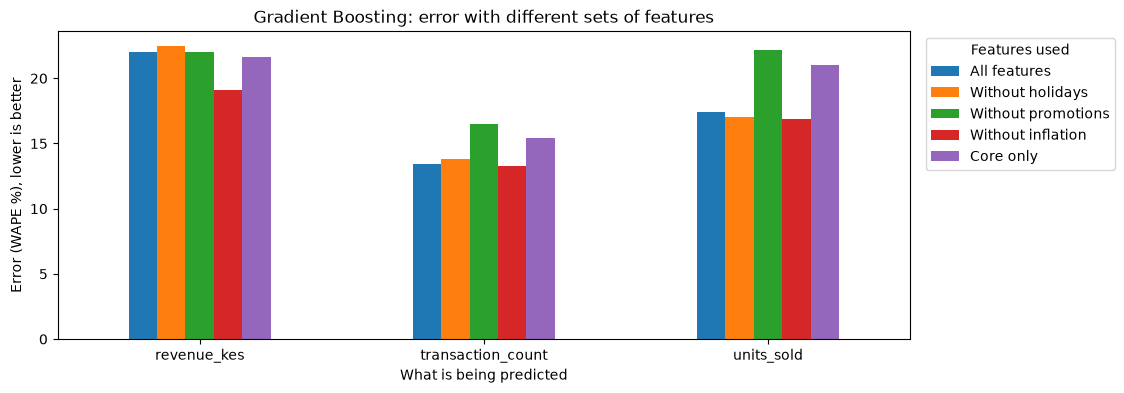

Features used,All features,Without holidays,Without promotions,Without inflation,Core only
Target,,,,,
revenue_kes,22.00,22.50,22.00,19.10,21.60
transaction_count,13.40,13.80,16.50,13.30,15.40
units_sold,17.40,17.00,22.20,16.90,21.00


In [29]:
monthly_removable_features = {"is_holiday": "holidays", "discount_pct": "promotions", "inflation_12m_pct": "inflation"}

compare_features(monthly_features, monthly_removable_features, X_train, y_train, X_validation, y_validation, "Gradient Boosting")

_For monthly forecasting, removing promotions raises WAPE for transactions (13.4% to 16.5%) and units (17.4% to 22.2%) but not for revenue (22.0% either way), so promotions help for those two targets. Removing holidays changes WAPE by 0.5 points or less. Removing inflation does not hurt: WAPE falls slightly for transactions and units and by about 3 points for revenue (22.0% to 19.1%), so inflation is not helping the monthly model and may be hurting it, although with only 3 validation months this is not reliable. The core model is worse for transactions and units (by 2–4 points) but about the same for revenue._

## Side by Side comparison for Weekly and Monthly models

In [30]:
test_results = []
test_predictions = {}

for forecast, data, period_column, features, period_name in [
        ("Weekly", weekly_data, "week_start", weekly_features, "weeks"),
        ("Monthly", monthly_data, "month_start", monthly_features, "months")]:

    X_train, y_train, _, _, X_test, y_test = split_by_time(data, period_column, features, period_name)

    boost_pred = fit_predict("Gradient Boosting", X_train, y_train, X_test)
    forest_pred = fit_predict("Random Forest", X_train, y_train, X_test)
    test_predictions[forecast] = (boost_pred, forest_pred)

    results = [model_scores("Baseline", y_test, previous_period_baseline(X_test)),
               model_scores("Gradient Boosting", y_test, boost_pred),
               model_scores("Random Forest", y_test, forest_pred)]
    test_results.append(pd.concat(results).assign(Forecast=forecast))

final_table = pd.concat(test_results).pivot_table(index=["Forecast", "Target"], columns="Model", values=["MAE", "WAPE (%)"])
final_table

Training weeks: 71 | Validation weeks: 15 | Test weeks: 16
Training months: 16 | Validation months: 3 | Test months: 4


MAE                                 WAPE (%)  \
Model                      Baseline Gradient Boosting Random Forest Baseline   
Forecast Target                                                                
Monthly  revenue_kes        6582.65           5375.40       5056.50    24.90   
         transaction_count    13.45             10.39         10.70    17.60   
         units_sold           35.37             25.61         25.16    25.10   
Weekly   revenue_kes        2821.03           1824.00       1876.22    47.10   
         transaction_count     6.58              3.98          4.04    37.90   
         units_sold           14.02              8.81          8.89    44.00   

                                                            
Model                      Gradient Boosting Random Forest  
Forecast Target                                             
Monthly  revenue_kes                   20.30         19.10  
         transaction_count             13.60         14.00  
         units_sold                    18.20         17.90  
Weekly   revenue_kes                   30.40         31.30  
         transaction_count             22.90         23.30  
         units_sold                    27.60         27.90

_Monthly forecasts are more accurate than weekly ones for every target (revenue error about 19–20% monthly vs 30–31% weekly), because adding up a month's sales smooths out week-to-week noise. The models improve on the baseline much more at weekly level (15–17 points) than monthly (4–7 points), since last week's sales are a poor guess while last month's are already a decent one. At both levels revenue is the hardest target, transactions the easiest, and the two models perform almost the same. With only 4 test months, the monthly scores are less reliable._

### Actual vs Predicted Sales

- Tables

In [31]:
def prediction_comparison(data, boost_predictions, forest_predictions, period_column):
    targets = ["revenue_kes", "units_sold", "transaction_count"]

    comparison = data.loc[boost_predictions.index, [period_column] + targets].copy()

    for target in targets:
        comparison["GB_" + target] = boost_predictions[target]
        comparison["RF_" + target] = forest_predictions[target]
    return comparison.groupby(period_column).sum().round(2)

weekly_boost_predictions, weekly_forest_predictions = test_predictions["Weekly"]
monthly_boost_predictions, monthly_forest_predictions = test_predictions["Monthly"]
weekly_comparison = prediction_comparison(weekly_data, weekly_boost_predictions, weekly_forest_predictions, "week_start")
monthly_comparison = prediction_comparison(monthly_data, monthly_boost_predictions, monthly_forest_predictions, "month_start")

display(weekly_comparison)
display(monthly_comparison)

,revenue_kes,units_sold,transaction_count,GB_revenue_kes,RF_revenue_kes,GB_units_sold,RF_units_sold,GB_transaction_count,RF_transaction_count
week_start,,,,,,,,,
2026-06-08,6503413.90,35474.00,19571.00,6431283.11,6650012.84,34678.19,35592.35,19496.13,19608.46
2026-06-15,6446729.70,34778.00,19493.00,6366771.30,6650711.28,35362.95,37123.60,19641.72,20113.10
2026-06-22,8807548.00,48652.00,26387.00,9039801.82,9529854.41,48705.30,50720.32,27176.78,27595.37
2026-06-29,9209398.10,49895.00,27387.00,8702122.44,9215181.40,46944.28,49014.72,26504.41,26856.14
2026-07-06,6006110.20,31966.00,18006.00,6491228.06,6661265.99,34824.11,34794.95,19757.03,19394.61
2026-07-13,6850246.55,36109.00,20387.00,6261781.70,6600728.53,33305.25,34771.44,18918.37,19080.95
2026-07-20,6969911.85,36395.00,19786.00,6415007.34,6745243.62,33545.61,35572.65,19101.47,19620.77
2026-07-27,13233286.05,68128.00,38143.00,11595576.57,11239803.80,61352.54,59057.29,33499.58,32213.52
2026-08-03,6808647.40,35462.00,19935.00,6939410.29,6942909.73,37061.01,35061.58,20988.20,19536.83


,revenue_kes,units_sold,transaction_count,GB_revenue_kes,RF_revenue_kes,GB_units_sold,RF_units_sold,GB_transaction_count,RF_transaction_count
month_start,,,,,,,,,
2026-06-01,32334437.80,177032.00,97210.00,35169421.58,32546845.80,187080.91,181373.38,98682.22,96938.17
2026-07-01,35581510.45,185980.00,103868.00,36567895.60,34485202.64,188557.38,178675.10,103198.53,99693.00
2026-08-01,38134958.79,201096.00,107483.00,38559769.24,37106542.25,205053.00,194581.27,109452.83,104871.98
2026-09-01,35642226.31,191560.00,101487.00,37644171.39,39229649.54,200268.49,206993.06,106559.54,108989.42


_Added up across all stores and products, both models follow the weekly pattern closely, including the month-end (payday) spikes, with an error of about 5% on weekly totals and 2–4% on monthly totals. This is much lower than the row-level scores because individual errors partly cancel out. The largest spike (week of 27 July) is underpredicted by 12–15%._

- Visual Charts

In [ ]:
# Plots actual and predicted totals for each target
def plot_all_targets(comparison, title):
    targets = ["revenue_kes", "units_sold", "transaction_count"]
    labels = ["Revenue (KES)", "Units sold", "Transactions"]
    fig, axes = plt.subplots(1, 3, figsize=(20, 4))

    for ax, target, label in zip(axes, targets, labels):
        comparison.plot( ax=ax, y=[target, "GB_" + target, "RF_" + target],
        legend=(target == targets[0]))

        ax.set_ylim(bottom=0)
        ax.set_ylabel(label)
        ax.set_title(label)
        ax.tick_params(axis="x", rotation=45)

    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

plot_all_targets(weekly_comparison, "Weekly: Actual vs Predicted")
plot_all_targets(monthly_comparison, "Monthly: Actual vs Predicted")

_Both models follow the weekly pattern closely, including the month-end (payday) spikes, but underpredict the highest peak (week of 27 July). Monthly, with only 4 points, both follow the overall trend but overpredict September, when actual sales dipped._

**Final model: Gradient Boosting.** On the validation set it had the lower error on every weekly target and on monthly units and transactions; the random forest was better only for monthly revenue. The test results agree for the weekly forecast (revenue WAPE 30.4% vs 31.3%), and gradient boosting trains much faster (about 5 seconds against about 2 minutes weekly).

## 5. Saving the Predicted Values for Dashboard

In [ ]:
for forecast, data, period_column in [("Weekly", weekly_data, "week_start"), ("Monthly", monthly_data, "month_start")]:
    boost_pred, forest_pred = test_predictions[forecast]

    export = data.loc[boost_pred.index, [period_column, "store_id", "product_id", "category"] + target_columns]
    export = export.rename(columns={target: "actual_" + target for target in target_columns})
    for target in target_columns:
        export["gb_" + target] = boost_pred[target]
        export["rf_" + target] = forest_pred[target]

    export.to_csv(f"../Data/processed_data/{forecast.lower()}_predictions.csv", index=False)